# 第17章 多轮优化实战

## 本章导读

一轮改动已经能解释，多轮之后怎样核对最终收益？我们先手动完成一轮，再运行几项预设候选，阅读源码变化、失败记录与性能曲线，最后固定最终实现独立复测。

默认运行无需模型密钥，预设策略不会调用在线模型。在线模型实验在本章练习中显式开启。前置：[第16章](../chapter16/chapter16.ipynb)，对照阅读：[本章正文](../../../docs/part3-agent/chapter17/index.md)。


In [ ]:
%run ../../common/bootstrap.py

import json
import pandas as pd
from IPython.display import display
import hello_gpu as gpu
from hello_gpu import agentlab
cfg = gpu.settings()
env = gpu.environment()
env


## 17.1 选择一个能读懂结果的任务

继续用 FP16 向量加法，让每次改动都能解释。核心源码放在下面，接受的计算仍然是 `a + b`；我们先在相同任务下研究配置变化。


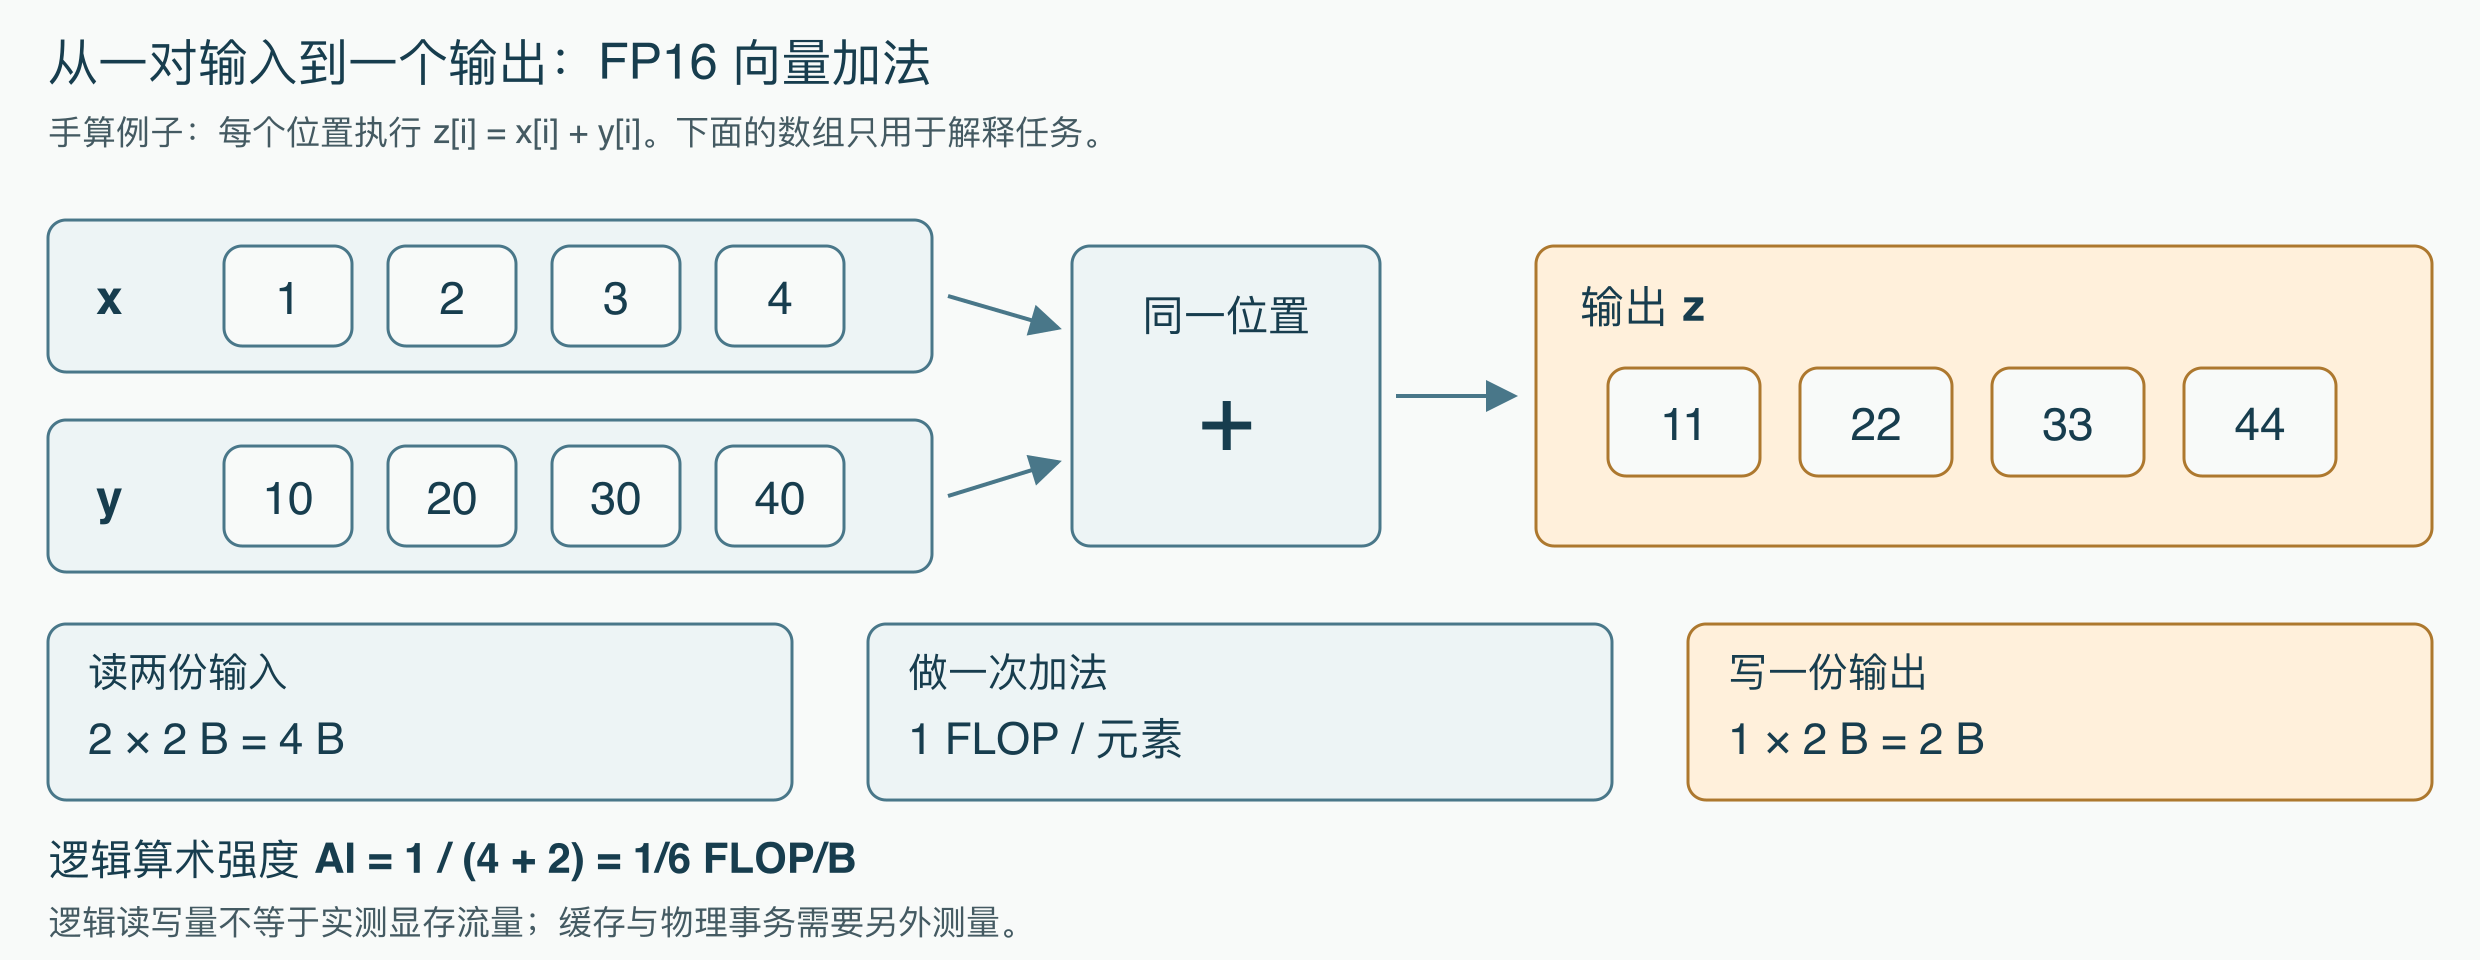

*本章固定数学语义与逻辑工作量；性能由当前设备的实际运行产生。*


In [ ]:
SOURCE = """import triton
import triton.language as tl

@triton.jit
def add_kernel(x, y, output, n_elements, BLOCK: tl.constexpr):
    offsets = tl.program_id(0) * BLOCK + tl.arange(0, BLOCK)
    valid = offsets < n_elements
    a = tl.load(x + offsets, mask=valid, other=0)
    b = tl.load(y + offsets, mask=valid, other=0)
    result = a + b
    tl.store(output + offsets, result, mask=valid)

def launch(x, y, output, n_elements):
    block_size = 256
    grid = (triton.cdiv(n_elements, block_size),)
    add_kernel[grid](x, y, output, n_elements, BLOCK=block_size,
                     num_warps=4)
"""
SOURCE = SOURCE.replace("block_size = 256", f"block_size = {cfg['block']}")


## 17.2 运行之前固定基线与记录范围

固定基线保存搜索开始前的实现，当前实现随接受判定更新。先测量基线并手动提交一项候选；后续轮次都保留成功与失败，不只记录最好的一次。


In [ ]:
lab = agentlab.Lab("chapter17", cfg, baseline_source=SOURCE)
display(pd.Series(lab.task_summary()))
baseline = lab.preflight()
agentlab.show(baseline, title="搜索前的固定基线")
assert baseline["ok"]


In [ ]:
manual_source = SOURCE.replace(f"block_size = {cfg['block']}",
                               f"block_size = {cfg['block'] * 2}")
agentlab.source_diff(SOURCE, manual_source)
manual_check = lab.step("bench_kernel", source=manual_source)
agentlab.show(manual_check, title="手动一轮：检查并计时")
assert manual_check["ok"]
manual_decision = lab.step("accept_candidate", source=manual_source,
                          change="手动一轮：block 扩两倍")
agentlab.show(manual_decision, title="手动一轮：接受判定")
_ = lab.pair_plot(manual_decision)


接着让预设策略组织几轮工具调用。先提交数值错误的版本，再尝试两个合法配置。策略不会根据反馈生成新的源码；它用真实 Agent 循环执行这些已知候选，帮助我们观察记录与状态。在线模型路径稍后单独运行。


In [ ]:
candidates = [
    {"change": "教学负例：加法改减法",
     "source": SOURCE.replace("result = a + b", "result = a - b")},
    {"change": "block 扩四倍",
     "source": SOURCE.replace(f"block_size = {cfg['block']}",
                              f"block_size = {cfg['block'] * 4}")},
    {"change": "block 扩八倍",
     "source": SOURCE.replace(f"block_size = {cfg['block']}",
                              f"block_size = {cfg['block'] * 8}")},
]
status = lab.run(candidates, max_steps=12, live=True)
lab.state_view()


**观察**：每轮先看实际行动与结果，再看下一轮。错误版本应留下失败记录；合法配置也可能没有改善。预设策略的模型调用次数为零，不把这个过程解释为模型自主推理。


## 17.3 先检查产物，再读性能数字

先核对搜索是否完成、是否还有待判定候选，以及每次行动是否留下记录。展开某轮评测卡可查看完整证据位置；失败也应保留，以便解释它为什么没有成为当前实现。


In [ ]:
assert status["state"] == "complete", "请先检查最后一步的状态和原因"
assert not status["pendingCandidate"]
trajectory = lab.table()
display(trajectory)
events = lab.events()
display(events[["step", "tool", "bestChanged"]])
assert (trajectory["status"] == "wrong_answer").any()


## 17.4 分清搜索曲线里的三种量

候选时间描述当轮源码；当前时间描述该轮结束时保留的实现；固定基线来自搜索前。单轮配对改善则比较候选与当时的当前实现。它们的参照对象不同，不能把每轮比例直接相乘当作最终收益。


In [ ]:
_ = lab.plot()


选一份候选，先看源码差异，再核对它对应的记录。修改下面的 `selected_round` 可以查看其他预设候选；是否接受应以表格中的实际判定为准。


In [ ]:
selected_round = 1  # 0 为错误示例；1、2 为两个合法配置
chosen = candidates[selected_round]
print("查看改动：", chosen["change"])
lab.inspect_round(change=chosen["change"])


## 17.5 独立复测回答整体收益

搜索结束后，冻结最终源码，与固定基线重新配对运行。复测不再挑新配置，也不使用搜索过程中最有利的一次样本。即使搜索接受了改动，复测仍可能显示波动或没有稳定改善。


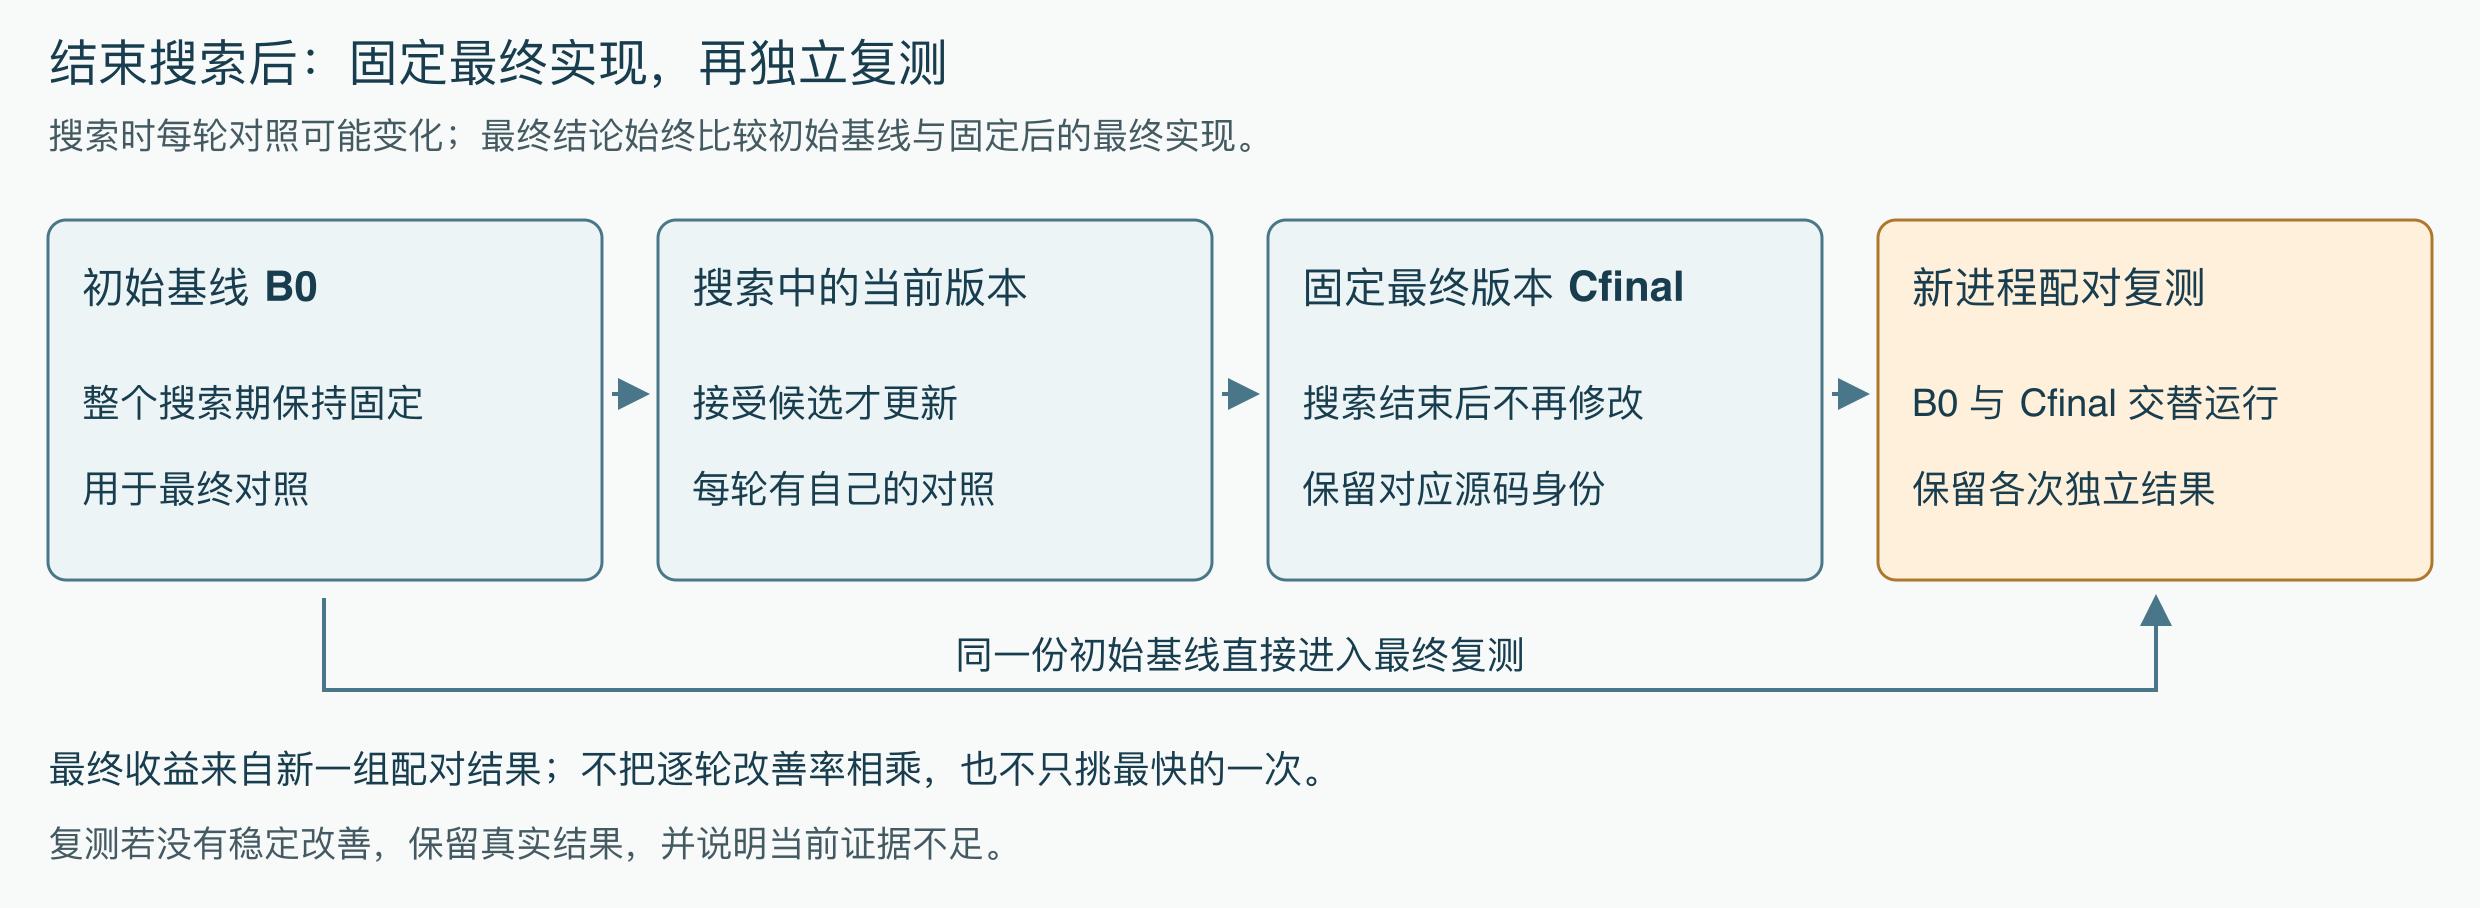

*搜索保留当前实现；搜索结束后冻结最终源码，再与固定基线重新配对测量。*


In [ ]:
final = lab.final_retest(runs=3)
_ = lab.retest_plot(final)
_ = lab.report(final)


**观察**：逐组比较复测样本，而不仅看一个比例。如果固定基线仍是最终实现，就如实报告没有获得稳定改善。结论只适用于本次任务、数据类型和设备。


## 17.6 写一份读者能核对的报告

报告应把最终结论连接到固定任务、源码、采样和接受记录。工具会保留完整证据；先用自己的话解释一项失败和一项合法尝试，再核对生成的报告。不要从计时直接推断未采集的硬件指标。


In [ ]:
my_explanation = {
    "一项失败": "减法版本改变了任务的数学语义，应由正确性检查拒绝。",
    "一项合法尝试": "扩大 block 的配置只按实际接受记录判断是否保留。",
    "结论边界": "当前任务、FP16 和本次 GPU；其他规模需重新测量。",
}
display(pd.Series(my_explanation))
agentlab.source_diff(lab.baseline_path.read_text(), lab.best_path.read_text())
_ = lab.report(final)


## 17.7 练习：完成一次可复盘的优化

先只改变输入规模或一个配置，重新走完整流程，并引用失败、接受和独立复测记录解释结果。接着可以把提出行动交给在线模型。

### 开启在线实验：先准备模型服务

先完成前面的基线与手动实验，再让模型提出下一步行动。在线实验需要当前 Python 内核已经安装 `litellm`、可以访问模型 API，并有一个支持工具调用（tool calling）的模型。我们仍在当前 GPU 上编译、对答案和计时；模型服务负责提出行动。

到模型服务的控制台准备三项信息：**模型 ID、API Base URL 和 API key**。模型 ID 使用控制台给出的 API 名称；API Base URL 使用服务文档给出的接口根地址，常见以 `/v1` 结尾，不能填写聊天网页地址或完整的 `/chat/completions` 地址。API key 是该服务创建的调用密钥。

本例使用 OpenAI 兼容的聊天接口。`openai/` 是 LiteLLM 的协议路由前缀，后面接服务实际提供的模型 ID；它也可以连接其他厂商的兼容服务。接口格式可对照 [LiteLLM 官方说明](https://docs.litellm.ai/docs/providers/openai_compatible)。

| 环境变量 | 在本章填写什么 | 示例或作用 |
| --- | --- | --- |
| `KERNEL_AGENT_MODEL` | `openai/` 加模型 ID | `openai/your-model-id` 中的 ID 要替换 |
| `KERNEL_AGENT_API_BASE` | API 的根地址 | `https://your-api-host/v1` 要替换为服务地址 |
| `KERNEL_AGENT_API_KEY` | 服务提供的 API key | 运行时通过隐藏输入框填写 |
| `KERNEL_AGENT_EXTRA_BODY` | 服务扩展参数的 JSON 对象 | 通用兼容接口先用 `{}`；需要关闭思考模式时按服务文档调整 |

### 第一步：在当前 Notebook 配置环境变量

先修改下面的 `MODEL`、`API_BASE` 和 `EXTRA_BODY`，再把 **`RUN_ONLINE = False` 改为 `True`**，运行这一格，在隐藏输入框粘贴 API key 并按 Enter。此时只配置当前 Python 进程，不发送模型请求。密钥不会写入源代码或单元格输出；重启内核后，需要重新运行配置并输入密钥。

`MAX_STEPS` 是 Agent 的模型决策循环步数上限，取值为 `1` 到 `100` 的整数。每一步可能返回多个工具调用，所以它不等于候选数量或工具调用次数，也不是费用上限。首次保持 `12`，随后根据实际轨迹调整。


In [ ]:
import os
from getpass import getpass

RUN_ONLINE = False
MAX_STEPS = 12
MODEL = "openai/your-model-id"
API_BASE = "https://your-api-host/v1"
EXTRA_BODY = {}

if RUN_ONLINE:
    if MODEL == "openai/your-model-id" or API_BASE == "https://your-api-host/v1":
        raise ValueError("请先把 MODEL 和 API_BASE 替换为服务实际提供的配置。")
    if not MODEL.startswith("openai/") or not MODEL.removeprefix("openai/").strip():
        raise ValueError("本例的 MODEL 格式为 openai/服务模型ID。")
    if not API_BASE.strip().startswith(("https://", "http://")):
        raise ValueError("API_BASE 需要是服务提供的完整 http:// 或 https:// 根地址。")
    if not isinstance(EXTRA_BODY, dict):
        raise ValueError("EXTRA_BODY 需要是 Python 字典，例如 {}。")
    api_key = getpass("请输入该模型服务的 API key（输入不可见）：").strip()
    if not api_key:
        raise ValueError("API key 不能为空，请重新运行这一格。")
    os.environ["KERNEL_AGENT_MODEL"] = MODEL.strip()
    os.environ["KERNEL_AGENT_API_BASE"] = API_BASE.strip().rstrip("/")
    os.environ["KERNEL_AGENT_API_KEY"] = api_key
    os.environ["KERNEL_AGENT_EXTRA_BODY"] = json.dumps(EXTRA_BODY)
    del api_key
    print("当前内核的在线配置已设置；尚未发送模型请求。")
else:
    print("在线实验未开启；修改配置并设 RUN_ONLINE = True 后再运行这一格。")


**配置示例**：如果使用 DeepSeek 官方的 OpenAI 兼容接口，可以将上一格的三个配置行改为下面的形式，再输入 DeepSeek API key。模型 ID 以服务当前提供的列表为准；此处是配置示例，不包含在线实测结果。

```python
MODEL = "openai/deepseek-flash"
API_BASE = "https://api.deepseek.com"
EXTRA_BODY = {"thinking": {"type": "disabled"}}
```

接口地址和模型名称见 [DeepSeek 官方接入说明](https://api-docs.deepseek.com/)。本章的循环没有维护思考模式的推理历史，因此示例关闭思考模式；相应参数见 [DeepSeek 思考模式说明](https://api-docs.deepseek.com/guides/thinking_mode)。其他服务使用自己的模型 ID、地址和扩展参数，不直接套用 DeepSeek 的 `thinking` 字段。

如果平台已经在 Python 内核中设置了这些环境变量，可以跳过上面的隐藏输入框配置，新增一个代码格，执行下面两行，再继续检查与运行。平台配置也需要按服务要求提供 `KERNEL_AGENT_EXTRA_BODY`：

```python
RUN_ONLINE = True
MAX_STEPS = 12
```

在 Notebook 中写 `os.environ["变量名"] = "值"` 会立即影响当前内核；在 Jupyter 终端执行 `export` 不会改变已经运行的 Python 内核。使用平台环境变量设置时，通常需要重启内核才能读取新值。

### 第二步：检查配置，暂不发送请求

运行下面这一格，确认 LiteLLM 已安装、模型名和 API 地址正确。密钥只显示是否已配置。已准备好的学习环境应提供这项依赖；默认的预设策略不需要它。

如果提示缺少 LiteLLM，可以新增一个代码格，执行下面的可选安装，再通过 **Kernel → Restart Kernel** 重启内核，从头运行本章并重新输入密钥。`%pip` 会给当前 Notebook 使用的 Python 安装依赖；正常运行无需重复安装。

```python
%pip install "litellm>=1.95"
```

如果提示 `No module named pip`，且环境提供了 `uv`，使用下面的替代安装格。`sys.executable` 指定当前内核的 Python，避免装到另一个环境；安装后同样重启内核并从头运行。

```python
import sys
!uv pip install --python "{sys.executable}" "litellm>=1.95"
```


In [ ]:
import os
from importlib.util import find_spec

if RUN_ONLINE:
    if find_spec("litellm") is None:
        raise RuntimeError("当前内核缺少 litellm，请先补齐在线实验依赖。")
    from kernel_optimize import llm
    configured_model, configured_base = llm._model_config()
    display(pd.Series({
        "模型": configured_model,
        "API 根地址": configured_base or "服务默认地址",
        "统一 API key 已配置": bool(os.environ.get("KERNEL_AGENT_API_KEY")),
        "模型决策步数上限": MAX_STEPS,
    }))
else:
    print("在线实验未开启，配置检查已跳过。")


### 第三步：启动在线循环并核对结果

运行下面这一格，先测量在线实验自己的 GPU 基线，再向配置的模型服务发送请求，可能产生服务费用。`live=True` 会逐步显示工具名与结果卡；每一步的模型消息、工具记录和评测结果保存在本次工作区中。

完成后查看 `online_status` 的状态、模型调用尝试次数和记录目录；调用尝试次数不包含 SDK 内部的 HTTP 重试统计。只有状态为 `complete`，才执行三次独立复测，它也不保证最终实现更快。`complete_with_warning` 表示已有有效裁决，但末尾仍有需要解释的尝试；先阅读报告中的限制。`incomplete` 表示实验尚未形成完整结论；先看状态与工具反馈，再决定是否增加 `MAX_STEPS`，重新运行这一格会创建新的实验工作区。


In [ ]:
if RUN_ONLINE:
    online_lab = agentlab.Lab("chapter17-online", cfg, baseline_source=SOURCE)
    online_baseline = online_lab.preflight()
    agentlab.show(online_baseline, title="在线实验的独立基线")
    assert online_baseline["ok"]
    online_status = online_lab.run_online(max_steps=MAX_STEPS, live=True)
    online_lab.state_view()
    display(pd.Series({key: online_status[key]
                       for key in ("state", "llmCalls", "workspace")}))
    if online_status["state"] == "complete":
        online_final = online_lab.final_retest(runs=3)
        _ = online_lab.retest_plot(online_final)
        _ = online_lab.report(online_final)
    else:
        print(online_status["report"])
        print("在线循环尚未完成，请先检查状态与工具反馈；本次不执行最终复测。")
else:
    print("在线实验未开启；本页默认流程的在线模型调用次数为 0。")


**遇到错误时**：先确定失败发生在模型接口还是 GPU 工具。下面列出接口配置的排查方向，具体原因以实际返回为准。

| 现象 | 先检查什么 |
| --- | --- |
| 缺少模型配置或格式错误 | 是否先运行了配置格；模型是否采用 `openai/模型ID` 格式 |
| `401` / `403` | 密钥是否属于当前服务，是否有该模型的调用权限 |
| `404` 或模型不存在 | API 根地址和模型 ID 是否与服务文档一致；不要把 `/chat/completions` 填进根地址 |
| `400`，涉及 `tools` 或 `tool_choice` | 模型和接口是否支持工具调用 |
| `400`，涉及扩展字段或思考历史 | `EXTRA_BODY` 是否符合当前服务要求；本章示例关闭思考模式 |
| `429`、超时或连接失败 | 服务限流、额度和当前内核到 API 的网络连通性 |

**观察**：对照预设策略与在线策略，记录模型实际提出的改动、工具返回的原因和独立复测结果。模型回复“完成”或“更快”仍需要工具证据支持。


## 本章小结

你已完成手动一轮、预设策略的多轮工具调用、轨迹核对和独立复测。应能区分候选、当前实现与固定基线，解释没有改善的结果，并让报告中的每一项结论对应实际证据。在线模型只是替换提出行动的方式，正确性与接受标准保持一致。


## 延伸阅读

- [本章正文](../../../docs/part3-agent/chapter17/index.md)
- [Triton 向量加法教程](https://triton-lang.org/main/getting-started/tutorials/01-vector-add.html)
